# Ćwiczenie 5: Przekształcenia lokalne w analizie obrazów medycznych
## Część 3: Filtry liniowe wygładzające

### 1. Dlaczego uśrednianie nie zawsze wystarcza?
Omówiony w Części 1 filtr uśredniający (Box Filter) działa bardzo agresywnie. Traktuje każdy piksel w otoczeniu (nawet ten daleko od centrum maski) z taką samą wagą. Powoduje to nienaturalne, sztuczne rozmycie krawędzi.

### 2. Filtr Gaussa
W radiologii standardem liniowej redukcji szumu jest **Filtr Gaussa**. Wagi w masce splotu są rozłożone zgodnie z dwuwymiarowym rozkładem normalnym:

$$G(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2+y^2}{2\sigma^2}}$$

Piksel centralny otrzymuje największą wagę, a wpływ sąsiadów maleje wykładniczo wraz z odległością. Kluczowym parametrem jest tu **$\sigma$ (odchylenie standardowe)**:
- **Mała $\sigma$:** Filtr usuwa tylko najdrobniejszy szum, zachowując detale.
- **Duża $\sigma$:** Maska staje się szeroka, silnie wygładza obraz, ale niszczy struktury o wysokiej częstotliwości przestrzennej (krawędzie kości, siatkę naczyń krwionośnych).

### 3. Zjawisko utraty ostrości krawędzi (Edge Blurring)
Każdy filtr liniowy z definicji rozmywa granice między tkankami. Poniżej użyjemy profilu liniowego, aby zmierzyć fizyczny spadek ostrości po filtracji Gaussa.

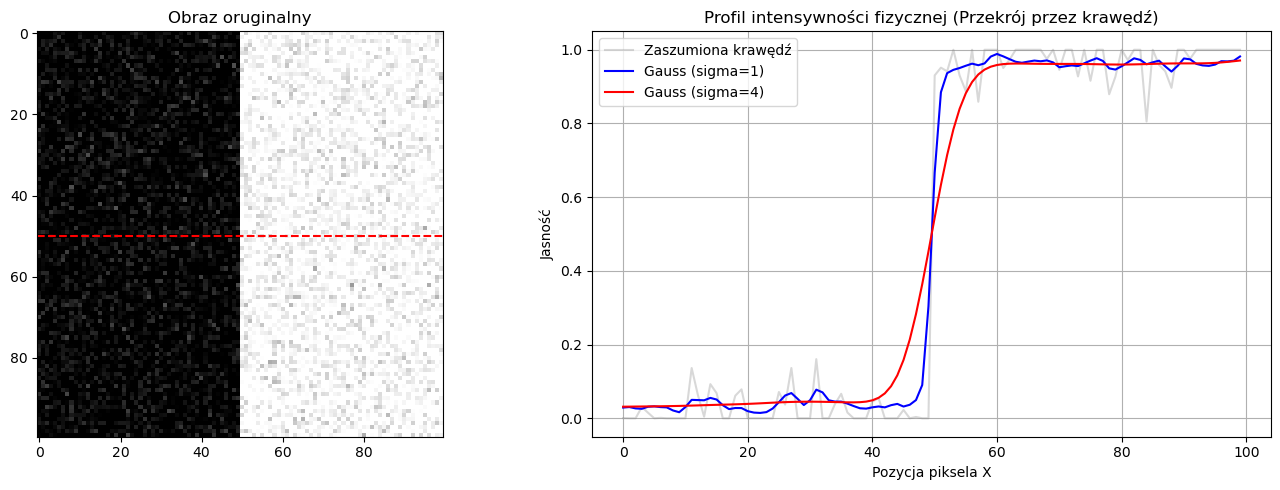

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util

# Przygotowanie obrazu z pionową krawędzią (np. symulacja przejścia tkanka/kość)
image = np.zeros((100, 100))
image[:, 50:] = 1.0
noisy_edge = util.random_noise(image, mode='gaussian', var=0.01)

# Zastosowanie filtru Gaussa o różnej sile
gauss_mild = filters.gaussian(noisy_edge, sigma=1.0)
gauss_strong = filters.gaussian(noisy_edge, sigma=4.0)

# Wyciągamy profil 1D (jeden wiersz) przecinający krawędź
row = 50
profile_noisy = noisy_edge[row, :]
profile_mild = gauss_mild[row, :]
profile_strong = gauss_strong[row, :]

# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(noisy_edge, cmap='gray')
axes[0].set_title('Obraz oruginalny')
axes[0].axhline(row, color='red', linestyle='--') # Zaznaczenie przekroju
'''
axes[0].imshow(gauss_mild, cmap='gray')
axes[0].set_title('Filtr Gaussa (sigma=1.0)')
axes[0].axhline(row, color='red', linestyle='--') # Zaznaczenie przekroju
'''
'''
axes[0].imshow(gauss_strong, cmap='gray')
axes[0].set_title('Filtr Gaussa (sigma=4.0)')
axes[0].axhline(row, color='red', linestyle='--') # Zaznaczenie przekroju
'''

axes[1].plot(profile_noisy, label='Zaszumiona krawędź', alpha=0.3, color='gray')
axes[1].plot(profile_mild, label='Gauss (sigma=1)', color='blue')
axes[1].plot(profile_strong, label='Gauss (sigma=4)', color='red')
axes[1].set_title('Profil intensywności fizycznej (Przekrój przez krawędź)')
axes[1].set_xlabel('Pozycja piksela X')
axes[1].set_ylabel('Jasność')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Komentarz:** Wykres po prawej pokazuje, że filtry liniowe "rozwlekają" skok jasności (tzw. funkcję LSF - Line Spread Function). Na zaszumionym obrazie skok od 0 do 1 następuje błyskawicznie. Po silnym filtrze Gaussa (czerwona linia) przejście zajmuje kilkanaście pikseli. Lekarz traci informację o rzeczywistej granicy anatomicznej.

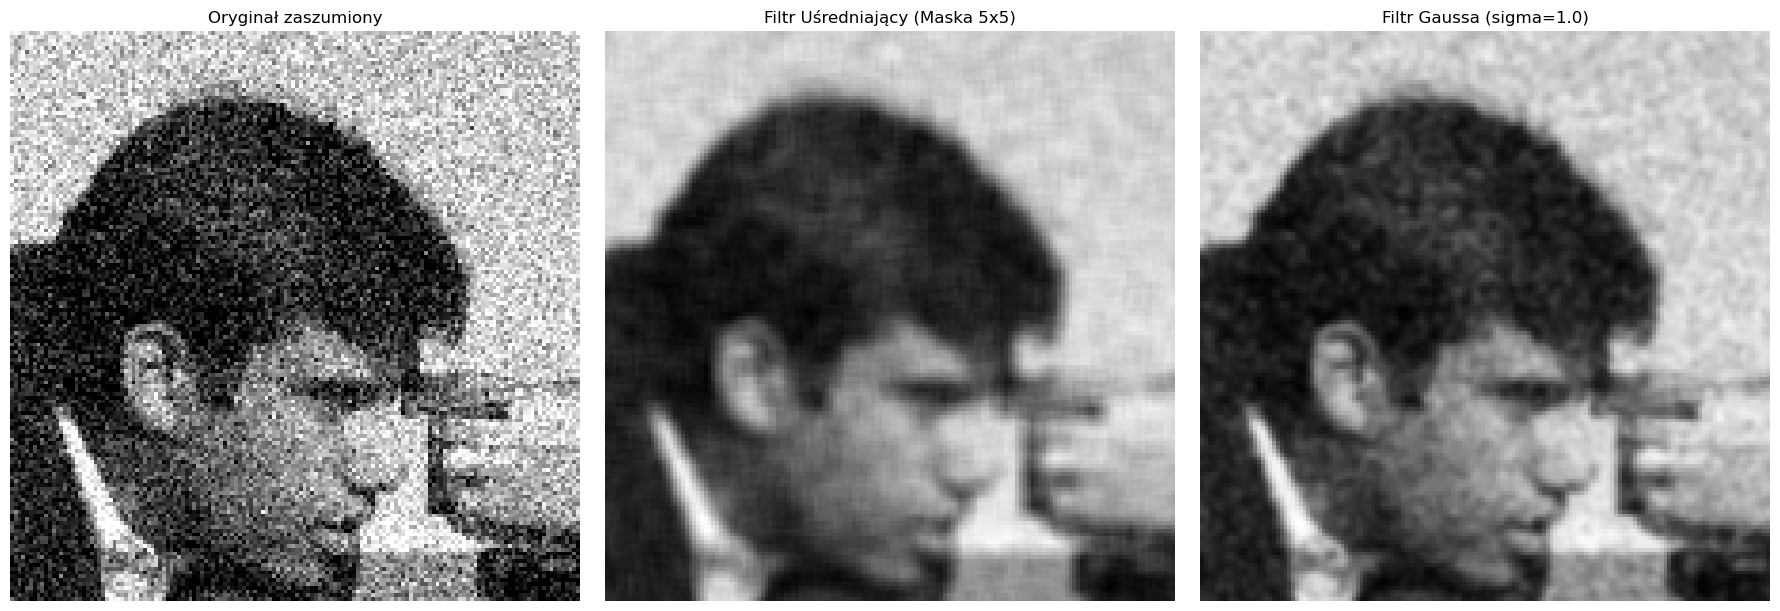

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util
from scipy.ndimage import convolve

# 1. Przygotowanie zaszumionego obrazu medycznego (tutaj na przykładzie standardowym)
image = data.camera() / 255.0
noisy_image = util.random_noise(image, mode='gaussian', var=0.02)

# 2. Filtr Uśredniający (Box Filter) - tworzymy ręcznie maskę 5x5
# Maska 5x5 ma 25 elementów, więc waga każdego to 1/25
kernel_box = np.ones((5, 5)) / 25.0
img_box = convolve(noisy_image, kernel_box, mode='reflect')

# 3. Filtr Gaussa (Dla sprawiedliwego porównania dobieramy sigma ~ odpowiadającą masce 5x5)
# W obrazowaniu medycznym często przyjmuje się zasadę kciuka: wielkość maski = 2 * int(3*sigma) + 1
# Dla maski ~5x5, użyjemy sigma ok. 1.0
img_gauss = filters.gaussian(noisy_image, sigma=1.0)

# Wizualizacja wyników z naciskiem na krawędzie (zbliżenie)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Zbliżenie na fragment z dużą ilością detali krawędzi (np. twarz/statyw)
slice_x, slice_y = slice(50, 200), slice(150, 300)

axes[0].imshow(noisy_image[slice_x, slice_y], cmap='gray')
axes[0].set_title('Oryginał zaszumiony')

axes[1].imshow(img_box[slice_x, slice_y], cmap='gray')
axes[1].set_title('Filtr Uśredniający (Maska 5x5)')

axes[2].imshow(img_gauss[slice_x, slice_y], cmap='gray')
axes[2].set_title('Filtr Gaussa (sigma=1.0)')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Wniosek i różnica w działaniu:**
Filtry liniowe (zarówno uśredniający, jak i Gaussa) działają podobnie – oba skutecznie wygładzają płaskie obszary, ale również rozmywają krawędzie (tzw. zjawisko *blurring*). 

Kluczowa różnica polega na mechanice wag:
*   **Filtr Uśredniający:** Piksel leżący na krawędzi maski 5x5 ma taki sam wpływ na wynik jak piksel centralny. Z tego powodu uśrednianie daje efekt "pudełkowy" (skokowy) na drobnych krawędziach.
*   **Filtr Gaussa:** Piksel centralny ma największą wagę, a im dalej od środka maski, tym waga płynnie maleje z godnie z kształtem dzwonu (krzywa Gaussa). Dzięki temu wygładzenie wydaje się bardziej naturalne i łagodne dla ludzkiego oka, dlatego Gauss stał się podstawowym narzędziem wygładzania liniowego w radiologii przed ewolucją w kierunku filtrów zachowujących krawędzie.